<a href="https://colab.research.google.com/github/anrghv/HEP-Tutorial/blob/main/XGB_tut_Hgg.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning Tutorial: Classifier Training on ROOT Data

In this tutorial we use Python and PyROOT to load particle physics data, build feature matrices, split into training and testing sets using event-ID parity (to avoid leakage), train an XGBoost classifier, and evaluate its performance.

**Contents**
0. Setup
1. Loading the signal data
2. Inspecting the data and selecting features
3. Building the feature matrices
4. Assigning labels
5. Train/test split by event parity
6. Event weights
7. Training the XGBoost classifier
8. Model evaluation: ROC and AUC
9. Overtraining check
10. Correlation analysis
11. Feature importance

## 0. Setup
We first install ROOT (PyROOT), which is needed to read experimental physics data (`.root` files) from Python, then import the core libraries.

In [1]:
!pip install ROOT

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 247.9/247.9 MB 21.9 MB/s  0:00:11


In [2]:
import ROOT
import numpy as np

/usr/local/lib/python3.13/dist-packages/ROOT/__init__.py:222: UserWarning: 
This distribution of ROOT is in alpha stage. Feedback is welcome and appreciated. Feel free to reach out to the user forum for questions and general feedback at https://root-forum.cern.ch or to submit an issue at https://github.com/root-project/root/issues. Do not rely on this distribution for production purposes.

  warnings.warn(


## 1. Loading the Signal Data
We create a ROOT `RDataFrame` on the `Events` tree of the signal sample (`ZHgg.root`). This is a lazy reference to the dataset; nothing is read yet.

In [4]:
df_sig = ROOT.RDataFrame("Events","ZHgg.root")


Warning in <TClass::Init>: no dictionary for class edm::Hash<1> is available
Warning in <TClass::Init>: no dictionary for class edm::ProcessHistory is available
Warning in <TClass::Init>: no dictionary for class edm::ProcessConfiguration is available
Warning in <TClass::Init>: no dictionary for class edm::ParameterSetBlob is available
Warning in <TClass::Init>: no dictionary for class pair<edm::Hash<1>,edm::ParameterSetBlob> is available


## 2. Inspecting the Data and Selecting Features
First we check how many columns (branches) the dataset has.

In [5]:
columns = df_sig.GetColumnNames()
# columns
print(len(columns))

# for col in columns:
    # if "ev" in col:
      # print(col)

1919


### Feature branch selection
We define the variables to read. The `event` number is read only so that we can split train/test later. It must **not** be used as a training feature, otherwise the model could learn arbitrary event-number patterns.

In [6]:
# NOTE: "event" is read only for the train/test split (section 5).
# It is NOT used as a training feature (see the feature matrices in section 3).
branches = ["ptll", "detajj", "PuppiMET_pt", "event", "detall"]

### Reading the signal tree into NumPy
`.AsNumpy()` exports the selected branches from ROOT into a dictionary of NumPy arrays.

In [7]:
# data = df.AsNumpy(["ptll", "detajj"])
data_sig = df_sig.AsNumpy(branches)
# data_all = df.AsNumpy() it will take all the branches in the root files

In [8]:
print(type(branches))
print(type(data_sig))
# print(type(data["ptll"]))
# print(len(data["ptll"]))
# print(len(data["detajj"]))

<class 'list'>
<class 'dict'>


In [9]:
print(data_sig['detajj'])

[0.62646484 0.33974314 0.4074707  ... 1.27160645 0.50341797 0.32641602]


In [10]:
# data is a dictionary with a structure like
# data = {
#     "ptll":   ndarray([...]),
#     "detajj": ndarray([...])
# }
print(data_sig.keys())

dict_keys(['ptll', 'detajj', 'PuppiMET_pt', 'event', 'detall'])


## 3. Building the Feature Matrices
### Signal matrix ($X_{\text{sig}}$)
We use `np.column_stack()` to stack the feature columns horizontally (excluding `event`).

In [11]:
X_sig = np.column_stack((data_sig["ptll"], data_sig["detajj"], data_sig["PuppiMET_pt"], data_sig["detall"]))
# X_sig = np.column_stack(list(data_sig.values()))
print("The type of the X is ",type(X_sig))
print("The shape ", X_sig.shape)

The type of the X is  <class 'numpy.ndarray'>
The shape  (4525, 4)


### Background matrix ($X_{\text{bkg}}$)
We repeat the same steps for the background sample (`DY.root`).

In [13]:
df_bkg = ROOT.RDataFrame("Events", "DY.root")
# creating dictionary for bkg

data_bkg = df_bkg.AsNumpy(branches)
print(type(data_bkg))
print(data_bkg.keys())

# creating the x_bkg matrix

X_bkg = np.column_stack((data_bkg["ptll"], data_bkg["detajj"], data_bkg["PuppiMET_pt"], data_bkg["detall"]))
# X_bkg = np.column_stack(list(data_bkg.values()))
print(type(X_bkg))
print(X_bkg.shape)

<class 'dict'>
dict_keys(['ptll', 'detajj', 'PuppiMET_pt', 'event', 'detall'])
<class 'numpy.ndarray'>
(51104, 4)


## 4. Assigning Labels
We create the binary ground-truth labels $Y$:
* **Signal** ($y_{\text{sig}}$) = $1$
* **Background** ($y_{\text{bkg}}$) = $0$

In [14]:
y_sig = np.ones(len(X_sig))
y_bkg = np.zeros(len(X_bkg))

In [15]:
print(len(X_sig), len(y_sig))
print(len(X_bkg), len(y_bkg))

4525 4525
51104 51104


### Combining signal and background
We concatenate the signal and background matrices and labels into single arrays.

In [16]:
# concatanete the two X_* matrices

X = np.concatenate((X_sig, X_bkg), axis=0)
print(X.shape)
X

(55629, 4)


array([[ 2.06337982e+02,  6.26464844e-01,  9.93958092e+00,
         1.46575928e-01],
       [-9.99900000e+03,  3.39743137e-01,  5.43982658e+01,
        -9.99900000e+03],
       [ 5.72839928e+01,  4.07470703e-01,  3.58351898e+01,
         1.95261765e+00],
       ...,
       [ 4.70178986e+01,  7.09521484e+00,  7.56127243e+01,
         8.07373047e-01],
       [ 1.12721605e+01, -9.99900000e+03,  1.40953369e+01,
         9.34814453e-01],
       [ 1.15456095e+01, -9.99900000e+03,  2.47724895e+01,
         1.74804688e+00]])

In [17]:
print(len(y_sig))
print(len(y_bkg))
len(y_sig)+len(y_bkg)

4525
51104


55629

In [18]:
Y = np.concatenate((y_sig, y_bkg), axis=0)
Y

array([1., 1., 1., ..., 0., 0., 0.])

## 5. Train/Test Split by Event Parity
To avoid the leakage of a random split, we split on the parity of the event ID: even events go to training, odd events to testing.

In [19]:
event_sig = data_sig["event"]
event_bkg = data_bkg["event"]

### Creating the training and testing masks

In [20]:
train_mask_sig = (event_sig %2  == 0)
test_mask_sig = event_sig % 2 != 0
train_mask_bkg = event_bkg %2  == 0
test_mask_bkg = event_bkg %2  != 0

print(train_mask_sig)
print(test_mask_sig)
print(train_mask_bkg)
print(test_mask_bkg)


[False False  True ...  True False  True]
[ True  True False ... False  True False]
[ True False False ...  True  True False]
[False  True  True ... False False  True]


### Applying the masks

In [21]:
X_sig_train = X_sig[train_mask_sig]
X_sig_test = X_sig[test_mask_sig]

X_bkg_train = X_bkg[train_mask_bkg]
X_bkg_test = X_bkg[test_mask_bkg]

In [22]:
print(X_sig_train.shape[0] + X_sig_test.shape[0])
print(len(X_sig))

4525
4525


### Combining the train and test partitions
We concatenate the signal and background partitions into unified training and testing matrices and label vectors.

In [23]:
X_train = np.concatenate((X_sig_train, X_bkg_train), axis=0)
X_test = np.concatenate((X_sig_test, X_bkg_test), axis=0)

In [24]:
y_sig_train = np.ones(len(X_sig_train))
y_sig_test = np.ones(len(X_sig_test))
y_bkg_train = np.zeros(len(X_bkg_train))
y_bkg_test = np.zeros(len(X_bkg_test))


y_train = np.concatenate((y_sig_train, y_bkg_train), axis=0)
y_test = np.concatenate((y_sig_test, y_bkg_test), axis=0)

print(y_train.shape)
print(y_test.shape)
print(X_train.shape)
print(X_test.shape)

(27966,)
(27663,)
(27966, 4)
(27663, 4)


## 6. Event Weights
We create dummy weights (random values) only to demonstrate how weights are passed to the classifier.

In [25]:
w_sig = np.random.uniform(0.5,2.0, size = len(X_sig_train))
w_bkg = np.random.uniform(0.5,2.0, size = len(X_bkg_train))

w_train = np.concatenate((w_sig, w_bkg), axis=0)
w_train

array([0.70318012, 1.65089839, 1.50543485, ..., 1.1244788 , 1.64717415,
       1.73247322])

## 7. Training the XGBoost Classifier
We initialise an `XGBClassifier` with `max_depth = 3` and 100 sequential trees (to limit overfitting) and train it on the training matrix.

In [26]:
from xgboost import XGBClassifier

In [27]:
model = XGBClassifier(n_estimators = 100,
                      max_depth = 3,
                      learning_rate = 0.1)

model.fit(X_train, y_train, w_train)
# model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/xgboost/core.py:566: FutureWarning: Pass `sample_weight` as keyword args.
  warnings.warn(msg, FutureWarning)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

### Predicting on the test set
`predict_proba(...)[:, 1]` returns the probability assigned to class 1 (signal).

In [28]:
y_test_score = model.predict_proba(X_test)[:,1]
y_test_score_weighted = model.predict_proba(X_test)[:,1]
# [:,1] means take the probabilty assigned to class 1, ie signal

In [29]:
print(y_test_score)
print(y_test_score_weighted)

[7.2317052e-01 9.9864990e-01 9.9785870e-01 ... 2.7990618e-03 2.6408170e-04
 1.8437069e-03]
[7.2317052e-01 9.9864990e-01 9.9785870e-01 ... 2.7990618e-03 2.6408170e-04
 1.8437069e-03]


In [30]:
X_test.shape

(27663, 4)

In [31]:
len(y_test_score)
print(y_test_score.shape)

(27663,)


## 8. Model Evaluation: ROC and AUC
We evaluate performance with the Receiver Operating Characteristic (ROC) curve and the Area Under the Curve (AUC), for both the training and testing sets:
* `y_test`: true labels
* `y_test_score`: classifier signal scores

In [32]:
from sklearn.metrics import roc_auc_score, roc_curve

In [33]:
y_test

array([1., 1., 1., ..., 0., 0., 0.])

In [34]:
y_train_score = model.predict_proba(X_train)[:,1]
print(len(y_train_score))

test_auc = roc_auc_score(y_test, y_test_score)
print(f"Testing auc is {test_auc: .3f}")

train_auc = roc_auc_score(y_train, y_train_score)
print(f"Training auc is {train_auc: .3f}")

print(f"Difference in test and train auc is {abs(train_auc-test_auc):.3f}")

27966
Testing auc is  0.974
Training auc is  0.977
Difference in test and train auc is 0.004


In [35]:

fpr_test, tpr_test, thresholds_test = roc_curve(y_test, y_test_score)
fpr_train, tpr_train, thresholds_train = roc_curve(y_train, y_train_score)

# print(type(fpr))
# print(type(tpr))
# print(type(thresholds))
# print(fpr)
# print(tpr.shape)
# print(thresholds.shape)

### ROC curve
We plot the true positive rate against the false positive rate at different thresholds. A good model arches towards the top-left corner (AUC close to 1.0).

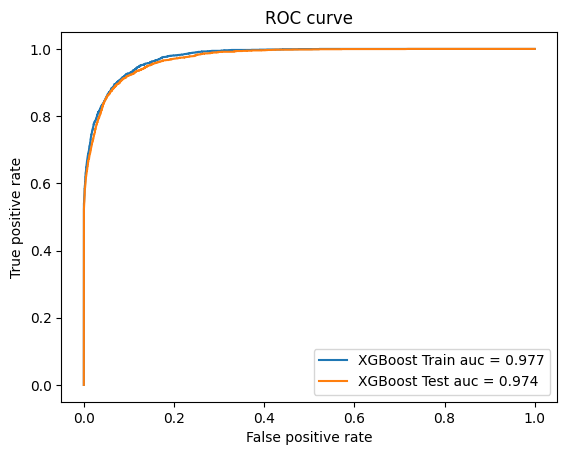

In [36]:
import matplotlib.pyplot as plt
plt.plot(fpr_train,
         tpr_train,
         label= f"XGBoost Train auc = {train_auc:.3f}")
plt.plot(fpr_test,
         tpr_test,
         label= f"XGBoost Test auc = {test_auc:.3f}")

plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve")

plt.legend()

## 9. Overtraining Check
We compare the BDT score distributions of the training and testing samples for signal and background.

* x-axis: BDT score
* y-axis: normalised event density
* Four distributions: signal/background × train/test

If there is no significant overtraining, the train and test distributions should roughly overlap. If they differ strongly (e.g. the training distribution is much sharper or more extreme), this indicates overtraining.

In [37]:
print("y_train =", y_train)
print("y_test =", y_test)
print("y_train_score =", y_train_score)
print("y_test_score =", y_test_score)

y_train = [1. 1. 1. ... 0. 0. 0.]
y_test = [1. 1. 1. ... 0. 0. 0.]
y_train_score = [3.5737422e-01 1.4136295e-01 9.9846458e-01 ... 4.6845540e-02 2.0219596e-02
 5.8822968e-04]
y_test_score = [7.2317052e-01 9.9864990e-01 9.9785870e-01 ... 2.7990618e-03 2.6408170e-04
 1.8437069e-03]


In [38]:
y_train_mask = y_train == 1
sig_train_scores = y_train_score[y_train_mask]
# print(sig_train_scores)

y_train_bkg_mask = y_train == 0
bkg_train_scores = y_train_score[y_train_bkg_mask]
# print(bkg_train_scores)

y_test_sig_mask = y_test ==1  # tells us which test events are signal
y_test_bkg_mask = y_test ==0

sig_test_scores = y_test_score[y_test_sig_mask]
bkg_test_scores = y_test_score[y_test_bkg_mask]


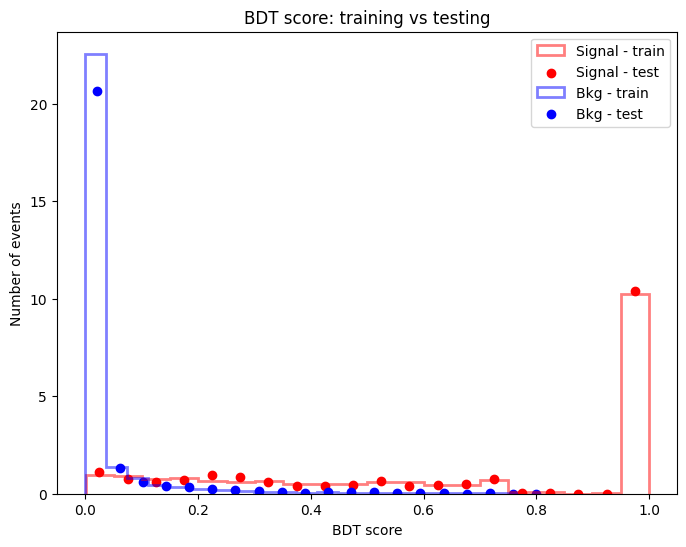

In [39]:
plt.figure(figsize=(8, 6))
plt.hist(sig_train_scores, bins = 20, alpha =0.5,histtype = "step", linewidth = 2, label  = "Signal - train", density = True, color = "r")
counts, bin_edges = np.histogram(sig_test_scores, bins = 20, density = True)
bin_centers = (bin_edges[:-1] + bin_edges[1:])/2
plt.scatter(bin_centers, counts, label = "Signal - test", color = "r")

plt.hist(bkg_train_scores, bins = 20, alpha =0.5,histtype = "step", linewidth = 2, label  = "Bkg - train",density = True, color = "b")
counts, bin_edges = np.histogram(bkg_test_scores, bins = 20, density = True)
bin_centers = (bin_edges[:-1] + bin_edges[1:])/2
plt.scatter(bin_centers, counts, label = "Bkg - test", color = "b")
plt.xlabel("BDT score")
plt.ylabel("Number of events")
plt.title("BDT score: training vs testing")
plt.legend()
plt.show()

## 10. Correlation Analysis
We evaluate the linear correlations among the training features.

In [40]:
features = [branch for branch in branches if branch != "event"]
features

['ptll', 'detajj', 'PuppiMET_pt', 'detall']

In [41]:
import pandas as pd


In [42]:
df_features = pd.DataFrame(X_train, columns = features)
corr = df_features.corr()
corr

,ptll,detajj,PuppiMET_pt,detall
ptll,1.000000,-0.194582,-0.248789,0.999875
detajj,-0.194582,1.000000,0.326576,-0.199232
PuppiMET_pt,-0.248789,0.326576,1.000000,-0.251001
detall,0.999875,-0.199232,-0.251001,1.000000


### Correlation heatmap

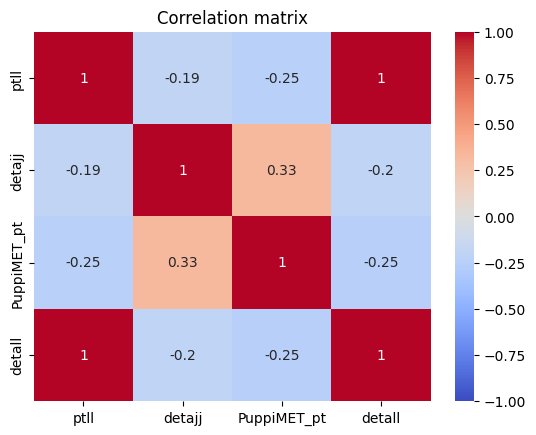

In [43]:
import seaborn as sns

sns.heatmap(corr,
            annot = True,
            cmap = "coolwarm",
            vmin = -1,
            vmax = 1)

plt.title("Correlation matrix")
plt.show()

## 11. Feature Importance
Finally, we inspect the relative importance XGBoost assigned to each feature, to see which variables drove the classification most.

In [44]:
importance = pd.DataFrame({
    "feature": features,
    "importance": model.feature_importances_
})
importance

,feature,importance
0,ptll,0.740001
1,detajj,0.178658
2,PuppiMET_pt,0.011667
3,detall,0.069673


In [45]:
# Now sort them

importance = importance.sort_values(
    "importance", ascending=False
)

importance

,feature,importance
0,ptll,0.740001
1,detajj,0.178658
3,detall,0.069673
2,PuppiMET_pt,0.011667


### Visualising feature importance

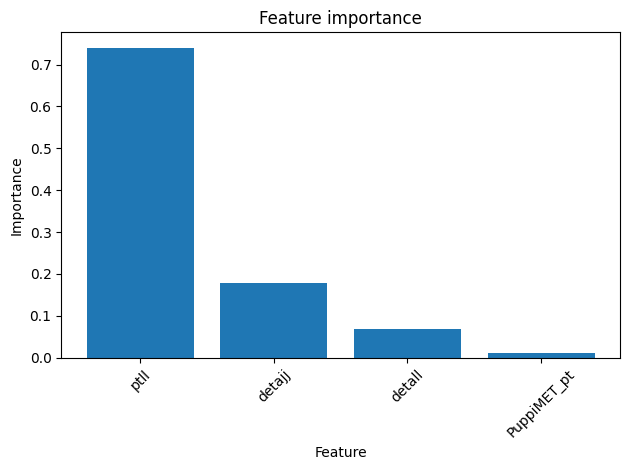

In [46]:
plt.bar(
    importance["feature"],
    importance["importance"],
)

plt.xlabel("Feature")
plt.ylabel("Importance")
plt.title("Feature importance")

plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()